# Multimodal Prompt Engineering with Google Gemini

## Overview

Gemini 2.5 Flash is a new language model from the Gemini family. This model introduces a breakthrough long context window of up to 1 million tokens that can help seamlessly analyze large amounts of information and long-context understanding. It can process text, images, audio, video, and code all together for deeper insights. Learn more about [Gemini 2.5](https://deepmind.google/technologies/gemini/flash/).

Here we will:

- analyze images for insights.
- analyze audio for insights.
- understand videos (including their audio components).
- extract information from PDF documents.
- process images, video, audio, and text simultaneously.

## Getting Started

### Install Google Gen AI library for Python


In [ ]:
!pip install google-generativeai==0.8.3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 160.8/160.8 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 760.0/760.0 kB 16.2 MB/s eta 0:00:00
  Attempting uninstall: google-ai-generativelanguage
    Found existing installation: google-ai-generativelanguage 0.6.15
    Uninstalling google-ai-generativelanguage-0.6.15:
      Successfully uninstalled google-ai-generativelanguage-0.6.15
  Attempting uninstall: google-generativeai
    Found existing installation: google-generativeai 0.8.5
    Uninstalling google-generativeai-0.8.5:
      Successfully uninstalled google-generativeai-0.8.5


## Enter API Tokens

In [ ]:
from getpass import getpass

GOOGLE_API_KEY = getpass('Enter Gemini API Key:')

Enter Gemini API Key:··········


### Import libraries


In [ ]:
import google.generativeai as genai

genai.configure(api_key=GOOGLE_API_KEY)

for m in genai.list_models():
  if 'generateContent' in m.supported_generation_methods:
    print(m.name)

models/gemini-2.5-pro-preview-03-25
models/gemini-2.5-flash-preview-05-20
models/gemini-2.5-flash
models/gemini-2.5-flash-lite-preview-06-17
models/gemini-2.5-pro-preview-05-06
models/gemini-2.5-pro-preview-06-05
models/gemini-2.5-pro
models/gemini-2.0-flash-exp
models/gemini-2.0-flash
models/gemini-2.0-flash-001
models/gemini-2.0-flash-exp-image-generation
models/gemini-2.0-flash-lite-001
models/gemini-2.0-flash-lite
models/gemini-2.0-flash-preview-image-generation
models/gemini-2.0-flash-lite-preview-02-05
models/gemini-2.0-flash-lite-preview
models/gemini-2.0-pro-exp
models/gemini-2.0-pro-exp-02-05
models/gemini-exp-1206
models/gemini-2.0-flash-thinking-exp-01-21
models/gemini-2.0-flash-thinking-exp
models/gemini-2.0-flash-thinking-exp-1219
models/gemini-2.5-flash-preview-tts
models/gemini-2.5-pro-preview-tts
models/learnlm-2.0-flash-experimental
models/gemma-3-1b-it
models/gemma-3-4b-it
models/gemma-3-12b-it
models/gemma-3-27b-it
models/gemma-3n-e4b-it
models/gemma-3n-e2b-it
models

### Load the Gemini 2.5 Flash model



In [ ]:
generation_config = genai.types.GenerationConfig(
    temperature=0
)
gemini = genai.GenerativeModel(model_name='gemini-2.5-flash',
                               generation_config=generation_config)

### LLM basic usage

Below is a simple example that demonstrates how to prompt the Gemini 1.5 Flash model using the API. Learn more about the [Gemini API parameters](https://cloud.google.com/vertex-ai/generative-ai/docs/model-reference/gemini#gemini-pro).

In [ ]:
from IPython.display import Markdown, display

prompt = """
  Explain what is Generative AI in 3 bullet points
"""

response = gemini.generate_content(contents=prompt)
display(Markdown(response.text))

Here are 3 bullet points explaining Generative AI:

*   **Creates New Content:** Generative AI is a type of artificial intelligence that can produce novel, original content (like text, images, code, or music) rather than just analyzing or classifying existing data.
*   **Learns from Patterns:** It learns patterns, structures, and styles from vast amounts of training data to understand how to generate plausible and often realistic outputs that resemble the data it was trained on.
*   **Mimics Creativity:** Users can prompt these models to generate specific content, effectively mimicking human creativity and producing diverse, unique results based on the learned distributions.

## Image Analysis

In [ ]:
# download images using curl
!curl https://i.imgur.com/6b9jwkk.png -o image1.png
!curl https://i.imgur.com/9CWuU2q.png -o image2.png

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  341k  100  341k    0     0  1125k      0 --:--:-- --:--:-- --:--:-- 1124k
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  347k  100  347k    0     0  1148k      0 --:--:-- --:--:-- --:--:-- 1149k


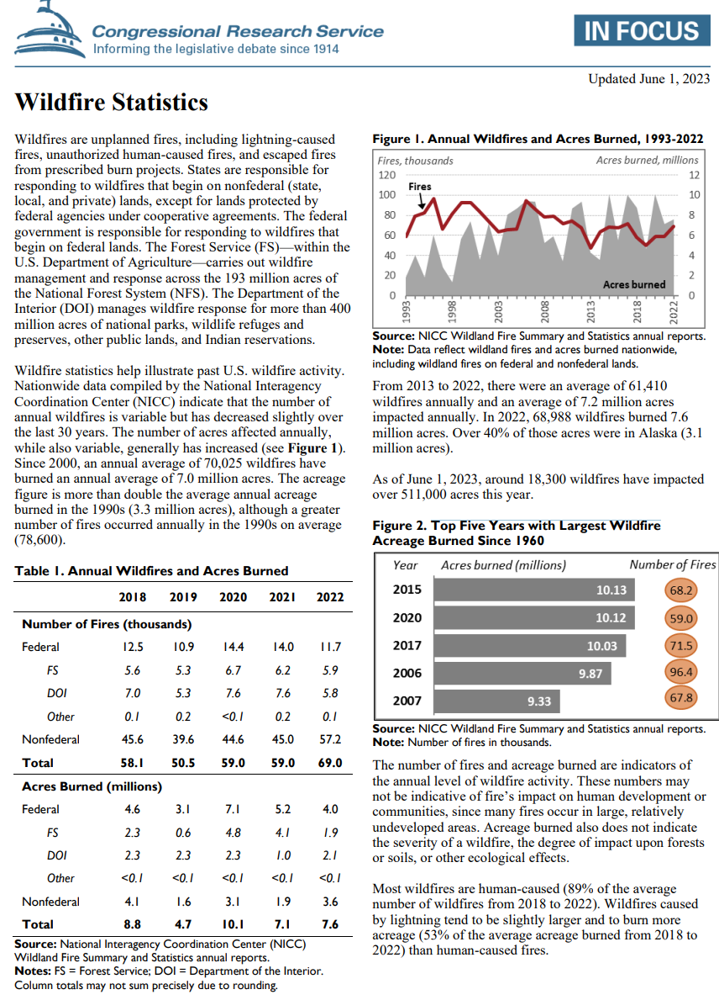

In [ ]:
from IPython.display import Image as ImageDisp, display

display(ImageDisp('image1.png'))

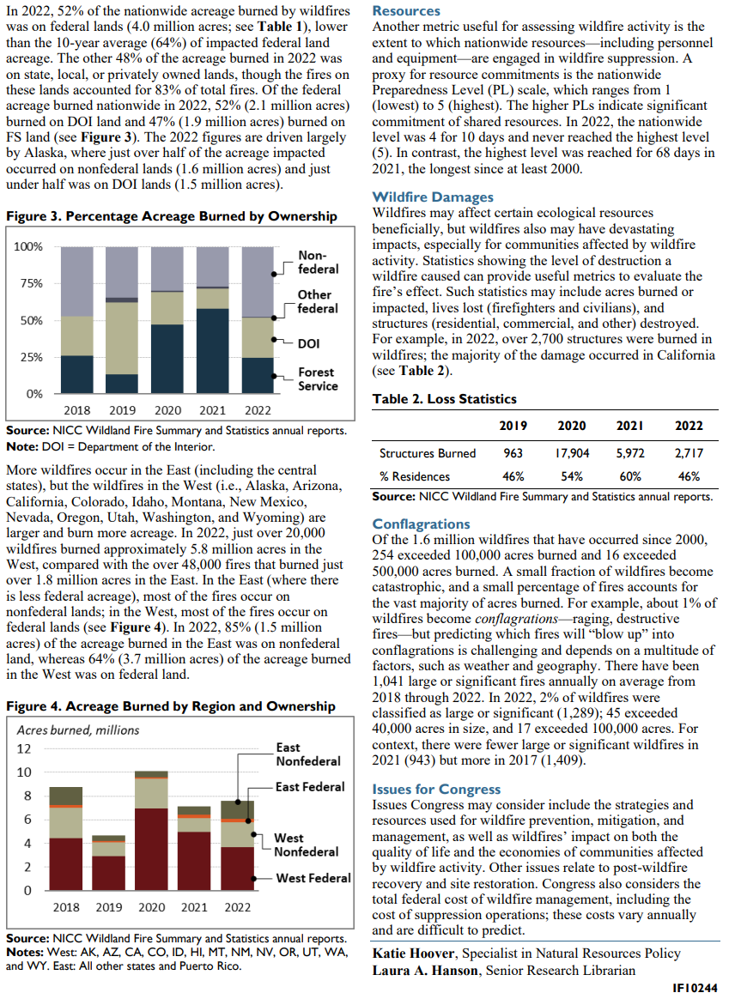

In [ ]:
display(ImageDisp('image2.png'))

In [ ]:
from PIL import Image

image1 = Image.open('image1.png')
image2 = Image.open('image2.png')

In [ ]:
prompt = """
  Given the following images which can contain graphs, tables and text,
  analyze all of them to answer the following question:

  Tell me about the top 5 years with largest Wildfires
"""

contents = [image1, image2,  prompt]
response = gemini.generate_content(contents)
display(Markdown(response.text))

Based on "Figure 2. Top Five Years with Largest Wildfire Acreage Burned Since 1960" from the provided document, the top 5 years with the largest wildfire acreage burned are:

1.  **2015:** 10.13 million acres
2.  **2020:** 10.12 million acres
3.  **2017:** 10.03 million acres
4.  **2006:** 9.87 million acres
5.  **2007:** 9.33 million acres

In [ ]:
prompt = """
  Given the following images which can contain graphs, tables and text,
  analyze all of them to answer the following question:

  Tell me about trend of wildfires in terms of acreage burned by region and ownership
"""

contents = [image1, image2,  prompt]
response = gemini.generate_content(contents)
display(Markdown(response.text))

Based on the provided figures and text, here's a summary of the trends in wildfires in terms of acreage burned by region and ownership:

1.  **Dominance of the Western United States:** The vast majority of acreage burned by wildfires consistently occurs in the Western United States. This trend is evident across all years from 2018 to 2022 in Figure 4. For instance, in 2022, approximately 5.8 million acres burned in the West, compared to about 1.8 million acres in the East.

2.  **Significant Impact on Federal Lands (Primarily in the West):**
    *   **Acreage:** Federal lands, particularly those managed by the Forest Service and the Department of the Interior (DOI), consistently account for the largest share of the *total acreage burned* nationwide. In 2022, 52% of the nationwide acreage burned (4.0 million acres) was on federal lands, predominantly in the West (Figure 4).
    *   **Percentage:** Figure 3 shows that Federal lands (Forest Service + DOI) often represent over 50% of the *percentage* of acreage burned annually.
    *   **Larger Fires:** While a greater *number of fires* often occur on nonfederal lands (83% of total fires in 2022), federal lands account for a larger proportion of the acreage burned, suggesting that fires on federal lands tend to be larger in size.

3.  **Contribution from Western Nonfederal Lands:** Nonfederal lands in the Western US also contribute significantly to the total acreage burned, though typically less than federal lands in the same region. Figure 4 illustrates this, showing substantial acreage burned on West Nonfederal lands each year.

4.  **Minimal Impact in the Eastern United States:** Wildfires in the Eastern US, both on federal and nonfederal lands, account for a comparatively small fraction of the total acreage burned nationwide. The bars for "East Federal" and "East Nonfederal" in Figure 4 are consistently much smaller than their Western counterparts.

## PDF Doc Analysis

In [ ]:
!wget https://arxiv.org/pdf/1706.03762.pdf

--2025-10-01 10:17:45--  https://arxiv.org/pdf/1706.03762.pdf
Resolving arxiv.org (arxiv.org)... 151.101.67.42, 151.101.195.42, 151.101.131.42, ...
Connecting to arxiv.org (arxiv.org)|151.101.67.42|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: /pdf/1706.03762 [following]
--2025-10-01 10:17:45--  https://arxiv.org/pdf/1706.03762
Reusing existing connection to arxiv.org:443.
HTTP request sent, awaiting response... 200 OK
Length: 2215244 (2.1M) [application/pdf]
Saving to: ‘1706.03762.pdf’

1706.03762.pdf      100%[===================>]   2.11M  --.-KB/s    in 0.09s   

2025-10-01 10:17:45 (24.0 MB/s) - ‘1706.03762.pdf’ saved [2215244/2215244]



In [ ]:
pdf_ref = genai.upload_file(path='./1706.03762.pdf')
pdf_ref

genai.File({
    'name': 'files/f7800bbw1n18',
    'display_name': '1706.03762.pdf',
    'mime_type': 'application/pdf',
    'sha256_hash': 'YmRmYWE2OGQ4OTg0ZjBkYzAyYmVhY2E1MjdiNzZmMjA3ZDk5YjY2NmQzMWQxZGE3MjhlZTA3MjgxODJkZjY5Nw==',
    'size_bytes': '2215244',
    'state': 'ACTIVE',
    'uri': 'https://generativelanguage.googleapis.com/v1beta/files/f7800bbw1n18',
    'create_time': '2025-10-01T10:18:15.699432Z',
    'expiration_time': '2025-10-03T10:18:15.468725721Z',
    'update_time': '2025-10-01T10:18:15.699432Z'})

In [ ]:
prompt = """
  Given the PDF file, use it to answer the following question:

  Tell me about the research paper mentioned here
"""

contents = [pdf_ref, prompt]

response = gemini.generate_content(contents)

Markdown(response.text)

This research paper, titled "**Attention Is All You Need**," introduces a groundbreaking neural network architecture called the **Transformer**.

Here's a summary of its key aspects:

1.  **Core Contribution:** The paper proposes the Transformer, a novel model architecture for sequence transduction tasks (like machine translation) that relies *solely* on attention mechanisms, completely dispensing with recurrent neural networks (RNNs) and convolutional neural networks (CNNs).

2.  **Motivation:** Traditional sequence models (RNNs, LSTMs) process information sequentially, which limits parallelization and makes learning long-range dependencies challenging due to long computational paths. While attention mechanisms were already used, they were typically combined with RNNs.

3.  **Key Innovations:**
    *   **Self-Attention and Multi-Head Attention:** The Transformer's core building block is the "Scaled Dot-Product Attention" and its extension, "Multi-Head Attention." This allows the model to weigh the importance of different parts of the input sequence when processing each element, capturing global dependencies directly.
    *   **Positional Encoding:** Since the model lacks recurrence or convolutions, it needs a way to incorporate information about the order of the sequence. This is achieved by adding "positional encodings" to the input embeddings.
    *   **Encoder-Decoder Structure:** It maintains the standard encoder-decoder architecture, where the encoder maps an input sequence to a continuous representation, and the decoder generates an output sequence one element at a time, using multi-head attention in various ways (self-attention in encoder, masked self-attention in decoder, and encoder-decoder attention).

4.  **Advantages:**
    *   **Superior Quality:** Achieved new state-of-the-art BLEU scores on WMT 2014 English-to-German (28.4 BLEU) and English-to-French (41.8 BLEU) translation tasks, outperforming existing models and even ensembles.
    *   **Increased Parallelization:** By removing sequential computation, the Transformer can process input elements in parallel, leading to significantly faster training times.
    *   **Reduced Training Time:** Achieved SOTA results in a fraction of the training cost of previous best models (e.g., 3.5 days on 8 GPUs for English-to-French).
    *   **Shorter Path Lengths:** Self-attention connects all positions with a constant number of operations, making it easier to learn long-range dependencies compared to RNNs (linear path length) or CNNs (logarithmic/linear path length).
    *   **Interpretability:** The attention mechanisms can offer insights into how the model relates different parts of the input and output sequences.

5.  **Generalization:** The paper also demonstrates the Transformer's ability to generalize to other tasks by successfully applying it to English constituency parsing, even with limited training data.

6.  **Authors and Affiliation:** The paper was primarily authored by researchers from Google Brain and Google Research, with contributions from the University of Toronto.

7.  **Impact:** "Attention Is All You Need" is a seminal paper in deep learning, particularly in Natural Language Processing. The Transformer architecture it introduced has become the foundational model for many modern large language models (LLMs) and has revolutionized sequence modeling across various domains. The code for the models was made available on GitHub.

## Audio understanding

Gemini 1.5 Flash can directly process audio for long-context understanding.


In [ ]:
!wget "https://storage.googleapis.com/cloud-samples-data/generative-ai/audio/pixel.mp3"

--2025-10-01 10:19:29--  https://storage.googleapis.com/cloud-samples-data/generative-ai/audio/pixel.mp3
Resolving storage.googleapis.com (storage.googleapis.com)... 172.217.164.27, 172.217.0.91, 172.217.12.27, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|172.217.164.27|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 5030643 (4.8M) [audio/mpeg]
Saving to: ‘pixel.mp3’

pixel.mp3           100%[===================>]   4.80M  --.-KB/s    in 0.03s   

2025-10-01 10:19:29 (139 MB/s) - ‘pixel.mp3’ saved [5030643/5030643]



In [ ]:
import IPython

IPython.display.Audio('./pixel.mp3')

In [ ]:
audio_file = genai.upload_file(path='./pixel.mp3')

In [ ]:
audio_file

genai.File({
    'name': 'files/rp38wt8h2660',
    'display_name': 'pixel.mp3',
    'mime_type': 'audio/mpeg',
    'sha256_hash': 'M2E4NTUyMmUwOGU1NGRiOWJhMjNmODVjNTk2M2Q5ZTk0ODUyMGY0YWVhOGYxNmY2ZGQ2NWYyMzg0Zjk3Y2IwZg==',
    'size_bytes': '5030643',
    'state': 'ACTIVE',
    'uri': 'https://generativelanguage.googleapis.com/v1beta/files/rp38wt8h2660',
    'create_time': '2025-10-01T10:19:36.359576Z',
    'expiration_time': '2025-10-03T10:19:36.090829175Z',
    'update_time': '2025-10-01T10:19:36.359576Z'})

#### Example 1: Title Generation

In [ ]:
prompt = """
  Please provide a summary for the audio.
  Provide chapter titles with timestamps, be concise and short, no need to provide chapter summaries.
  Do not make up any information that is not part of the audio and do not be verbose.
"""

contents = [audio_file, prompt]
response = gemini.generate_content(contents=contents)
print(response.text)

This podcast episode features Aisha Sharif and DeCarlos Love, product managers for Pixel devices, discussing the significance and impact of Google's "feature drops." They share their personal favorite transformative features, highlighting how these updates enhance user experience across the Pixel ecosystem, from phones and watches to tablets. The conversation delves into the recent January feature drop, detailing new functionalities like the mint color, body temperature sensor, Circle to Search, and Photo Emoji. The main focus is on the March feature drop, outlining new capabilities for Pixel Watch (including bringing features to older models, pace features, heart rate zones, activity recognition, and the Fitbit Relax app) and Pixel Phones (expanding Circle to Search, 10-bit HDR for Instagram, and partial screen sharing). Updates for other devices like tablets (app screen sharing, Docs Markup) and general Bluetooth connection improvements are also covered. The guests address a question

#### Example 2: Transcription

In [ ]:
prompt = """
    Can you transcribe this interview, in the format of [timecode] - [speaker] : caption.
    Use speaker A, speaker B, etc. to identify the speakers. Map each speaker to their real name at the start of the output
    Each speaker should have a single caption based on their starting timestamp
    Do not break up the transcript into multiple timestamps for the same speaker
    Show the output only for the part of the conversation about the pixel watch and follow the format mentioned above for the output
"""

contents = [audio_file, prompt]
response = gemini.generate_content(contents=contents)
print(response.text)

Here's the transcribed interview segment focusing on the Pixel Watch:

0:57 - Rashid Finch : Amazing. Decarlos, same question to you, but for Pixel Watch, of course, long-time listeners will know you work on Pixel Watch. What has been the most transformative feature in your own life on Pixel Watch?
1:07 - Decarlos Love : I work on the fitness experiences and so for me it's definitely the ability to track my heart rate, specifically around the different heart rate targets and zone features that we've released. For me it's been super helpful. My background is in more football, track and field and in terms of what I've done before and so using the heart rate features to really help me understand that I shouldn't be going as hard when I'm running, you know, leisurely two or three miles and helping me really tone that down a bit. It's actually been pretty transformative for me to see how things like my resting heart rate have a change due to that feature.
3:30 - Rashid Finch : Amazing. And 

#### Example 3: Summarization

In [ ]:
prompt = """
    Given the audio file, generate a comprehensive summary of:
     - Key Speakers
     - Key products and features discussed
     - Any other noteworthy discussions
"""

contents = [audio_file, prompt]
response = gemini.generate_content(contents=contents)
display(Markdown(response.text))

This podcast episode of "Made by Google" discusses the latest feature drops for Pixel devices, focusing on the March 2024 update and reflecting on previous ones.

**Key Speakers:**

*   **Rashid Finch:** Host
*   **Aisha Sharif:** Product Manager for Pixel devices
*   **Decarlos Love:** Product Manager for Pixel Watch

**Key Products and Features Discussed:**

**General Philosophy of Feature Drops:**
*   Devices are constantly improving, and feature drops help tell a "joint narrative" across the entire Pixel portfolio (phones, watches, buds, tablets).
*   Pixel 8 and 8 Pro will receive 7 years of OS updates, security updates, and feature drops, ensuring longevity and continuous improvement.
*   Feature drops enhance existing features, add new improvements, introduce completely new functionalities, and bring features from newer devices to older ones.

**Personal Most Transformative Features:**
*   **Aisha (Pixel Phone):** **Recorder Transcription** – Incredibly helpful for transcribing songs, even jumbled lyrics, as a singer.
*   **Decarlos (Pixel Watch):** **Heart Rate Tracking (targets and zones)** – Specifically the ability to track heart rate around different targets and zones, which helped him understand and adjust his running pace.

**January Feature Drop Highlights (Aisha):**
*   **New Mint Color:** Launched for Pixel 8 and 8 Pro.
*   **Body Temperature Sensor:** Launched in the US for Pixel 8 and 8 Pro, allowing users to scan their forehead for body temperature.
*   **Circle to Search (AI Enhancement):** Came to Pixel 8 and 8 Pro, enabling searching from anywhere on the screen.
*   **Photo Emoji:** Allows users to use photos from their album to react to messages.

**March Feature Drop Highlights:**

*   **For Pixel Watch (Decarlos):**
    *   **Bringing Features to Pixel Watch 1:** Many new features are being brought to the first-generation Pixel Watch.
    *   **Pace Features:** Allows users to set a target pace and receive notifications if they are ahead or behind during workouts.
    *   **Heart Rate Zones:** Similar to pace features, providing guidance based on heart rate zones.
    *   **Activity Recognition:** For Pixel Watch 1, this feature helps automatically start/stop workouts and provides notifications if users forget to end a workout.
    *   **Fitbit Relax App:** Now available on Pixel Watch 1, offering breathing exercises directly on the wrist.

*   **For Pixel Phones (Aisha):**
    *   **Circle to Search Expansion:** Now expanding to Pixel 7 and 7 Pro.
    *   **10-bit HDR Video:** Can now be captured and shared outside of the camera app, specifically available in Instagram for high-quality reels.
    *   **Partial Screen Sharing:** Allows users to share a specific app instead of their entire phone screen during meetings or casting, enhancing privacy.

*   **For Other Pixel Portfolio Devices (Aisha):**
    *   **App Screen Sharing:** Coming to Pixel Tablet.
    *   **Docs Markup:** Coming to Pixel Tablet (and also available on phones), allowing users to directly draw and take notes on documents.
    *   **Improved Bluetooth Connection:** Makes it easier to connect previously associated devices (e.g., if you connected buds to your phone, they'll automatically be recognized and easily connectable to your new Pixel Tablet).

**Favorite Past Feature Drops (from Aisha & Decarlos):**

*   **Aisha (Call Features):**
    *   **Call Screen Enhancement (December):** Provides contextual chips, allowing users to respond to specific call types (e.g., package delivery) without picking up.
    *   **Direct My Call for Non-Toll-Free Numbers:** Now works for local numbers (e.g., doctor's office), saving time.
    *   **Clear Calling:** Improves call audio quality.

*   **Decarlos (Pixel Watch):**
    *   **SpO2 Feature:** Measures oxygen saturation, allowing users to track it overnight while sleeping.
    *   **Relax App (Design):** Specifically highlighted the attention to detail in the design and breathing animations within the app.

**Other Noteworthy Discussions:**

*   **Decision-Making for Feature Drops:**
    *   Driven by the core principle of making devices continuously better.
    *   Consideration of technical feasibility (e.g., new sensors might limit older gen devices).
    *   **User feedback is paramount:** It helps identify what users value, what features are helpful, and guides what comes next.

*   **March Feature Drop Release Date:** All features discussed for the March drop will start rolling out **today, March 4th**.

## Video with audio understanding

Try out Gemini 1.5 Flash’s native multimodal and long context capabilities on video interleaving with audio inputs.

In [ ]:
!wget "https://storage.googleapis.com/cloud-samples-data/generative-ai/video/pixel8.mp4"

--2025-10-01 10:20:23--  https://storage.googleapis.com/cloud-samples-data/generative-ai/video/pixel8.mp4
Resolving storage.googleapis.com (storage.googleapis.com)... 172.217.164.27, 172.217.0.91, 172.217.12.27, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|172.217.164.27|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 4951975 (4.7M) [video/mp4]
Saving to: ‘pixel8.mp4’

pixel8.mp4          100%[===================>]   4.72M  --.-KB/s    in 0.06s   

2025-10-01 10:20:23 (78.5 MB/s) - ‘pixel8.mp4’ saved [4951975/4951975]



In [ ]:
IPython.display.Video('pixel8.mp4', embed=True, width=450)

In [ ]:
video_file = genai.upload_file(path='./pixel8.mp4')

In [ ]:
prompt = """
  Provide a comprehensive summary of the video.
  The summary should also contain anything important which people discuss in the video.
"""

contents = [video_file, prompt]

response = gemini.generate_content(contents=contents)
display(Markdown(response.text))

The video features Saeka Shimada, a photographer in Tokyo, who shares her perspective on the city's unique character, particularly at night. She emphasizes that the nighttime city is "totally different from what you see during the day."

The main focus of the video is to introduce a new feature on the Pixel phone called "Video Boost" (coming soon, Pixel 8 Pro only, requires Google Photos app). Saeka explains that in low-light conditions, this feature activates "Night Sight" to significantly improve video quality.

She takes her Pixel phone to Sancha, a neighborhood in Tokyo that holds special memories for her as it was where she first lived after moving to the city. She is shown actively filming various scenes in a narrow, atmospheric alleyway filled with small shops and lanterns. She captures details like reflections in puddles and the general ambiance of the bustling night street. Her reactions, such as "Oh, I like this" and an excited "Beautiful!" after seeing the boosted footage, clearly indicate her satisfaction with the enhanced video quality.

The video visually demonstrates the "Video Boost" effect by showing a dramatic before-and-after comparison of a dark alleyway transforming into a bright, clear, and vibrant scene. A montage of various night shots, showcasing improved clarity and color, further highlights the feature's capabilities.

Finally, Saeka moves to Shibuya, another iconic Tokyo location, where she and her friends are seen enjoying the city lights, seemingly impressed by the visual experience.

In [ ]:
!gdown -O 'awsq_video.mp4' '1shnBXeuXYcbRr9IhxofHkT3rlSaqPG1e'

Downloading...
From: https://drive.google.com/uc?id=1shnBXeuXYcbRr9IhxofHkT3rlSaqPG1e
To: /content/awsq_video.mp4
100% 4.53M/4.53M [00:00<00:00, 13.3MB/s]


In [ ]:
IPython.display.Video('awsq_video.mp4', embed=True, width=450)

In [ ]:
vid = genai.upload_file(path='./awsq_video.mp4')

In [ ]:
prompt = """
  Provide a description of the video.
  The description should cover the key steps covered in the video in bullet points
"""

contents = [vid, prompt]
response = gemini.generate_content(contents)
display(Markdown(response.text))

This video demonstrates the functionality of an Amazon Q Business application, showcasing how it uses custom knowledge to answer user queries.

Here are the key steps covered in the video:

*   **Viewing Uploaded Data Sources:** The video starts by showing the "Uploaded files" data source within the "q-assistant" application in Amazon Q Business. It lists three PDF documents ("attention_paper.pdf", "resnet_paper.pdf", "vision_transformer.pdf") that have been successfully indexed.
*   **Reviewing Application Settings:** The application details page for "q-assistant" is briefly shown, confirming its successful creation and general settings.
*   **Managing User Access:** The "Users and groups" tab is displayed, indicating that a specific user ("Dipanjan Sarkar") has been added to access the application.
*   **Interacting with the Amazon Q Chatbot:** The video then switches to the Amazon Q chat interface to demonstrate its capabilities.
*   **Querying Custom Knowledge:** A query "describe self attention in detail" is entered. Amazon Q provides a detailed answer, referencing the previously uploaded documents as sources.
*   **Demonstrating Knowledge Scope:** A subsequent query "who won the champions league in 2023" is entered. Amazon Q responds that it "could not find relevant information," highlighting that its answers are based on the custom knowledge provided (i.e., the uploaded documents) and not general internet knowledge.

Gemini 1.5 Pro model is able to process the video with audio, retrieve and extract textual and audio information.

## All modalities (images, video, audio, text) at once

Gemini 1.5 Pro is natively multimodal and supports interleaving of data from different modalities, it can support a mix of audio, visual, text, and
code inputs in the same input sequence.

In [ ]:
!wget 'https://storage.googleapis.com/cloud-samples-data/generative-ai/video/behind_the_scenes_pixel.mp4'

--2025-10-01 10:21:38--  https://storage.googleapis.com/cloud-samples-data/generative-ai/video/behind_the_scenes_pixel.mp4
Resolving storage.googleapis.com (storage.googleapis.com)... 172.217.0.91, 172.217.12.27, 2607:f8b0:4025:803::201b, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|172.217.0.91|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 39519854 (38M) [video/mp4]
Saving to: ‘behind_the_scenes_pixel.mp4.1’

behind_the_scenes_p 100%[===================>]  37.69M   198MB/s    in 0.2s    

2025-10-01 10:21:39 (198 MB/s) - ‘behind_the_scenes_pixel.mp4.1’ saved [39519854/39519854]



In [ ]:
!wget 'https://storage.googleapis.com/cloud-samples-data/generative-ai/image/a-man-and-a-dog.png'

--2025-10-01 10:21:39--  https://storage.googleapis.com/cloud-samples-data/generative-ai/image/a-man-and-a-dog.png
Resolving storage.googleapis.com (storage.googleapis.com)... 172.217.0.91, 172.217.12.27, 2607:f8b0:4025:803::201b, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|172.217.0.91|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 4376280 (4.2M) [image/png]
Saving to: ‘a-man-and-a-dog.png.1’

a-man-and-a-dog.png 100%[===================>]   4.17M  --.-KB/s    in 0.03s   

2025-10-01 10:21:39 (141 MB/s) - ‘a-man-and-a-dog.png.1’ saved [4376280/4376280]



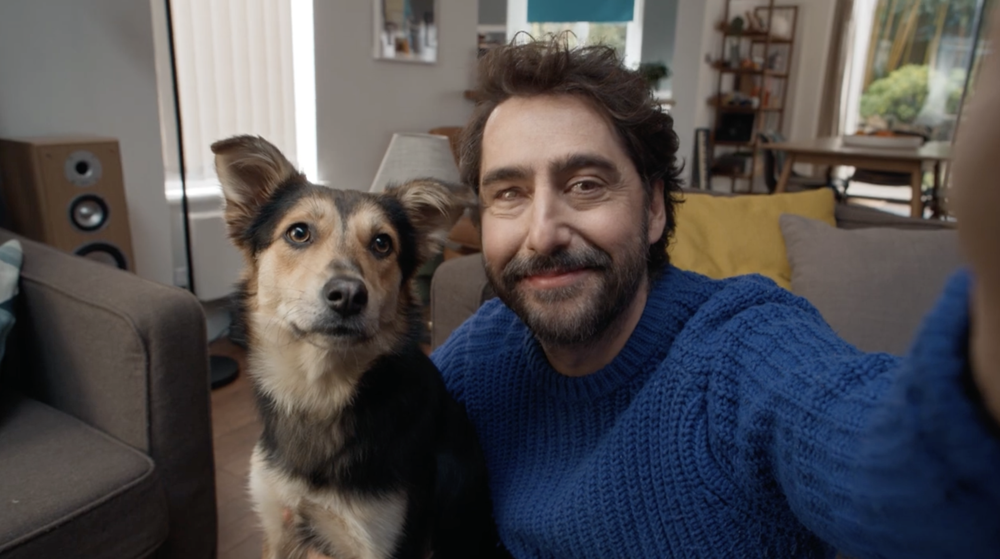

In [ ]:
IPython.display.Image('a-man-and-a-dog.png', width=450)

In [ ]:
video_file = genai.upload_file(path='./behind_the_scenes_pixel.mp4')
image_file = genai.upload_file(path='./a-man-and-a-dog.png')

In [ ]:
prompt = """
  Look through each frame in the video carefully and answer the questions.
  Only base your answers strictly on what information is available in the video attached.
  Do not make up any information that is not part of the video and summarize your answer
  in three bullet points max

  Questions:
  - When is the moment in the image happening in the video? Provide a timestamp.
  - What is the context of the moment and what does the narrator say about it?
"""

contents = [video_file, image_file, prompt]
response = gemini.generate_content(contents)
display(Markdown(response.text))

Here's the information about the image:

*   **Timestamp:** 0:48
*   **Context:** The image shows a man and his dog taking a selfie. This is presented as a clear photo, contrasting with subsequent blurred images that simulate low vision.
*   **Narrator's statement:** The narrator introduces the film's story, stating, "The story is about a blind man and his girlfriend, and we follow them on their journey together and growing closer."

## Conclusion

In this tutorial, you've learned how to use the Gemini 1.5 Flash to:

- analyze images for insights.
- analyze PDF docs for insights.
- analyze audio for insights.
- understand videos (including their audio components).
- process images, video, audio, and text simultaneously.